In [1]:
import pandas as pd

df = pd.read_csv('/content/train.csv')

df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


# Black Friday Sales Analysis

## Introduction

Black Friday is one of the biggest shopping events, where customers purchase products at discounted prices. This project focuses on analysing Black Friday sales data to understand customer purchasing behaviour, product preferences, and spending patterns.

Using Python and data analysis techniques, we will explore the dataset and identify useful business insights that can help companies improve their sales strategies.

In [2]:
df.shape

(550068, 12)

## Problem Statement

Businesses often find it difficult to understand customer purchasing behaviour during large shopping events like Black Friday. They need to identify which products are popular, how customer demographics influence purchases, and how much customers spend.

This project aims to analyse Black Friday sales data to understand these patterns and provide meaningful insights for better business decision-making.

## Objectives

- To analyse customer purchasing behaviour.
- To identify popular product categories.
- To understand purchasing patterns based on gender and age.
- To analyse the relationship between customer demographics and spending.
- To identify useful trends and insights from Black Friday sales data.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


## Understanding the Dataset

The dataset contains information about customers, their demographic details, product categories, and purchase amounts during the Black Friday sale. It helps us understand customer preferences and purchasing trends.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


In [5]:
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [6]:
df.isnull().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,173638


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,173638


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

User_ID                        0.000000
Product_ID                     0.000000
Gender                         0.000000
Age                            0.000000
Occupation                     0.000000
City_Category                  0.000000
Stay_In_Current_City_Years     0.000000
Marital_Status                 0.000000
Product_Category_1             0.000000
Product_Category_2            31.566643
Product_Category_3            69.672659
Purchase                       0.000000
dtype: float64


In [10]:
# Check missing values
df.isnull().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,173638


In [11]:
df['Product_Category_2'] = df['Product_Category_2'].fillna(0)
df['Product_Category_3'] = df['Product_Category_3'].fillna(0)

print("Missing values handled successfully!")

Missing values handled successfully!


In [12]:
df.isnull().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,0


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset through statistical summaries and visualisations. It helps identify patterns, trends, and relationships in customer purchasing behaviour.

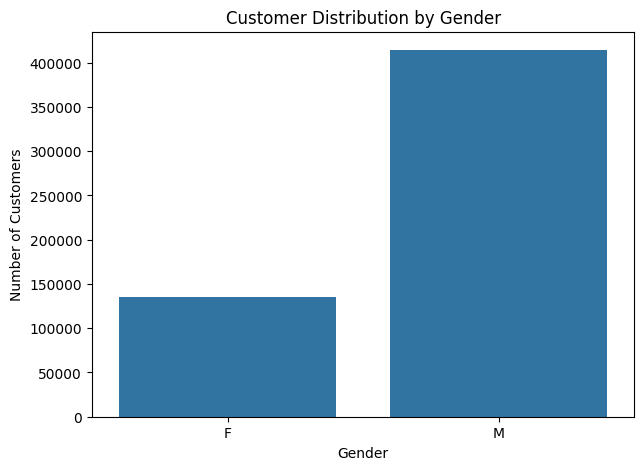

In [13]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

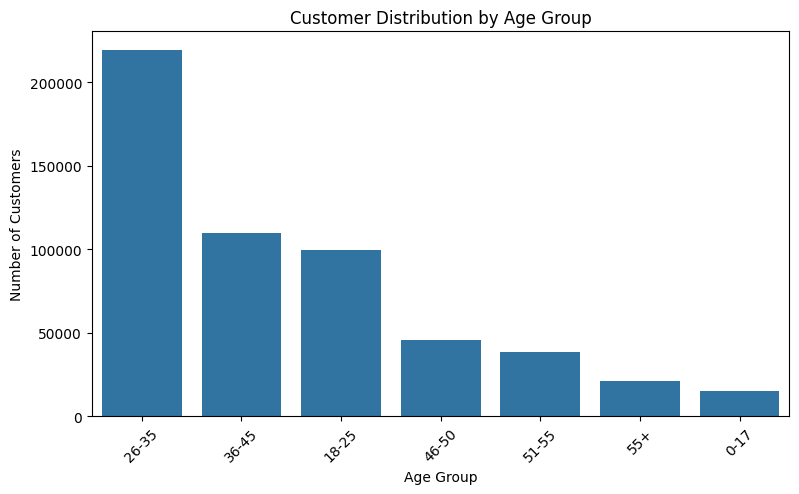

In [14]:
plt.figure(figsize=(9,5))

sns.countplot(data=df, x='Age', order=df['Age'].value_counts().index)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

In [15]:
age_purchase = df.groupby('Age')['Purchase'].mean()

print(age_purchase)

Age
0-17     8933.464640
18-25    9169.663606
26-35    9252.690633
36-45    9331.350695
46-50    9208.625697
51-55    9534.808031
55+      9336.280459
Name: Purchase, dtype: float64


## Product Category Analysis

This analysis helps identify which product categories are most popular among customers during Black Friday sales. It also helps businesses understand customer product preferences.

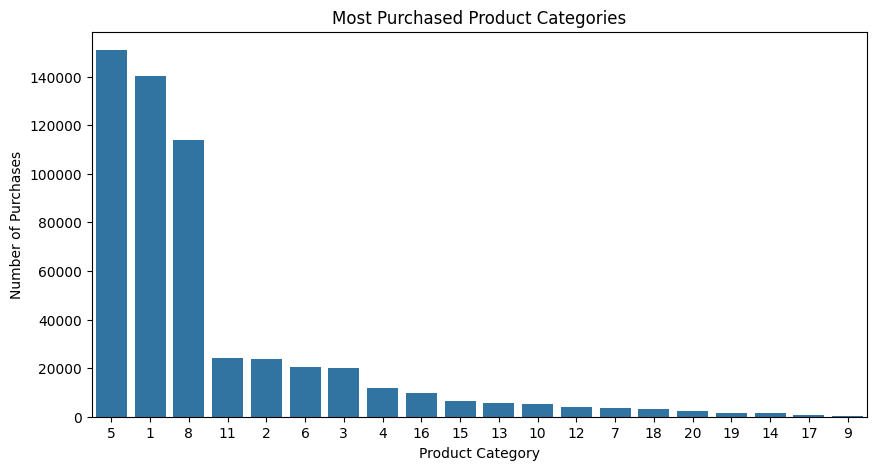

In [16]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='Product_Category_1',
              order=df['Product_Category_1'].value_counts().index)

plt.title('Most Purchased Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')

plt.show()

## Purchase Amount Analysis

This analysis focuses on understanding how much customers spend during Black Friday sales. It helps identify spending patterns and the distribution of purchase amounts.

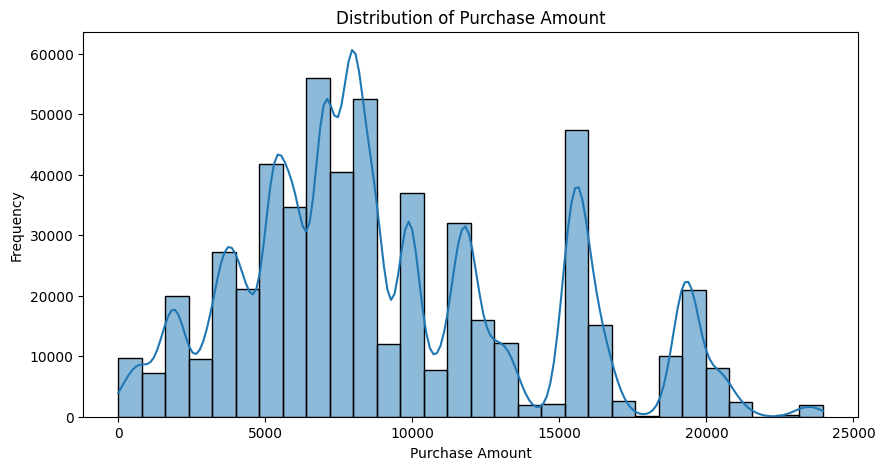

In [17]:
plt.figure(figsize=(10,5))

sns.histplot(df['Purchase'], bins=30, kde=True)

plt.title('Distribution of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.ylabel('Frequency')

plt.show()

In [18]:
gender_purchase = df.groupby('Gender')['Purchase'].mean()

print(gender_purchase)

Gender
F    8734.565765
M    9437.526040
Name: Purchase, dtype: float64


## City-wise Sales Analysis

This analysis helps us understand customer purchasing behaviour across different city categories. It identifies which city category contributes more to customer purchases during Black Friday sales.

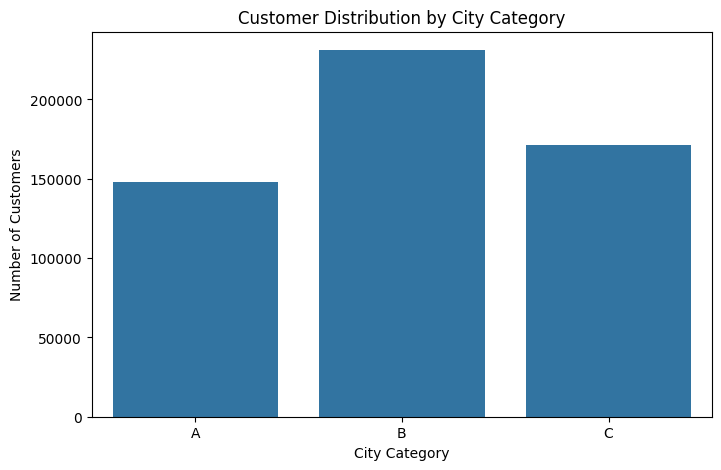

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='City_Category',
              order=['A', 'B', 'C'])

plt.title('Customer Distribution by City Category')
plt.xlabel('City Category')
plt.ylabel('Number of Customers')

plt.show()

In [20]:
city_purchase = df.groupby('City_Category')['Purchase'].mean()

print(city_purchase)

City_Category
A    8911.939216
B    9151.300563
C    9719.920993
Name: Purchase, dtype: float64


## Marital Status Analysis

This analysis examines the purchasing behaviour of married and unmarried customers during Black Friday sales. It helps understand whether marital status has any relationship with customer spending patterns.

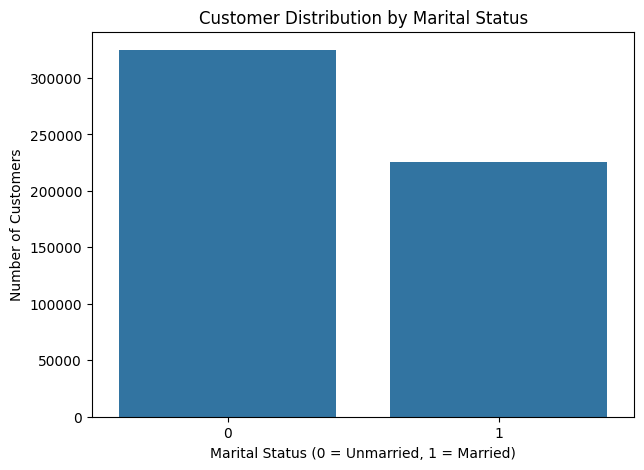

In [21]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Marital_Status')

plt.title('Customer Distribution by Marital Status')
plt.xlabel('Marital Status (0 = Unmarried, 1 = Married)')
plt.ylabel('Number of Customers')

plt.show()

In [22]:
marital_purchase = df.groupby('Marital_Status')['Purchase'].mean()

print(marital_purchase)

Marital_Status
0    9265.907619
1    9261.174574
Name: Purchase, dtype: float64


## Top 10 Most Purchased Products

This analysis identifies the ten most frequently purchased products during Black Friday sales. It helps businesses understand customer demand and popular product choices.

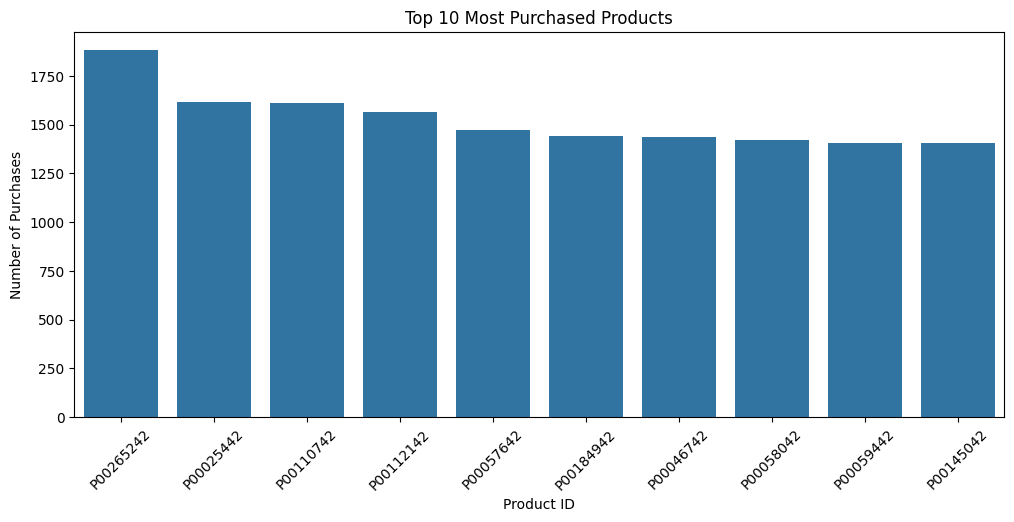

In [23]:
top_products = df['Product_ID'].value_counts().head(10)

plt.figure(figsize=(12,5))

sns.barplot(x=top_products.index, y=top_products.values)

plt.title('Top 10 Most Purchased Products')
plt.xlabel('Product ID')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)

plt.show()

In [24]:
print(top_products)

Product_ID
P00265242    1880
P00025442    1615
P00110742    1612
P00112142    1562
P00057642    1470
P00184942    1440
P00046742    1438
P00058042    1422
P00059442    1406
P00145042    1406
Name: count, dtype: int64


## Occupation-wise Purchase Analysis

This analysis studies customer purchasing behaviour based on their occupation. It helps identify which occupation groups contribute more to Black Friday purchases.

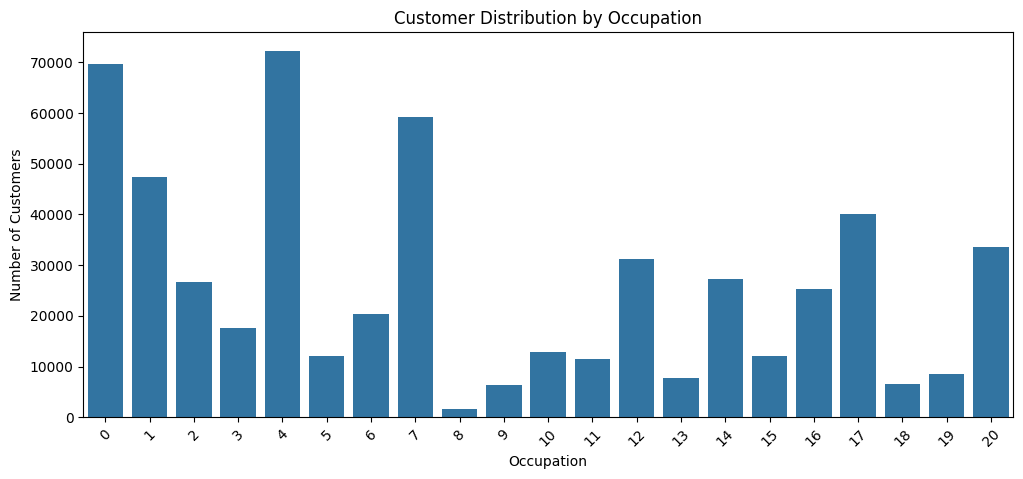

In [25]:
plt.figure(figsize=(12,5))

sns.countplot(data=df, x='Occupation')

plt.title('Customer Distribution by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

In [26]:
occupation_purchase = df.groupby('Occupation')['Purchase'].mean().sort_values(ascending=False)

print(occupation_purchase)

Occupation
17    9821.478236
12    9796.640239
15    9778.891163
8     9532.592497
14    9500.702772
7     9425.728223
16    9394.464349
5     9333.149298
13    9306.351061
6     9256.535691
4     9213.980251
11    9213.845848
3     9178.593088
18    9169.655844
0     9124.428588
10    8959.355375
1     8953.193270
2     8952.481683
20    8836.494905
19    8710.627231
9     8637.743761
Name: Purchase, dtype: float64


## Product Category-wise Purchase Analysis

This analysis compares the average spending across different product categories. It helps identify which categories generate higher purchase values during Black Friday sales.

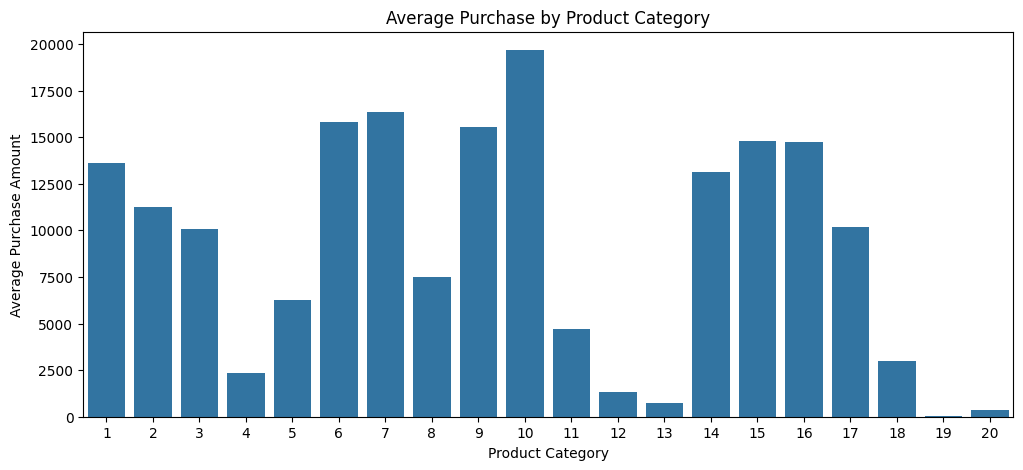

In [27]:
category_purchase = df.groupby('Product_Category_1')['Purchase'].mean().sort_values(ascending=False)

plt.figure(figsize=(12,5))

sns.barplot(x=category_purchase.index, y=category_purchase.values)

plt.title('Average Purchase by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Purchase Amount')

plt.show()

In [28]:
print(category_purchase.head(5))

Product_Category_1
10    19675.570927
7     16365.689600
6     15838.478550
9     15537.375610
15    14780.451828
Name: Purchase, dtype: float64


## Key Findings

The analysis of Black Friday sales data helps us understand several important aspects of customer purchasing behaviour.

- Gender analysis shows differences in male and female customer participation.
- Age group analysis helps identify the major customer segments.
- Product category analysis highlights popular product choices.
- City-wise analysis shows purchasing patterns across different city categories.
- Occupation analysis helps understand spending behaviour across customer groups.
- Purchase amount analysis provides insights into customer spending patterns.

## Business Recommendations

Based on the analysis, the following recommendations can help businesses improve their Black Friday sales:

1. **Targeted Marketing:** Focus marketing campaigns on age groups and customer segments that show higher purchasing activity.
2. **Product Availability:** Maintain sufficient stock of popular product categories to meet customer demand.
3. **Customer Segmentation:** Create different offers for customers based on their age, gender, occupation, and purchasing behaviour.
4. **Personalized Offers:** Provide suitable discounts and product recommendations to attract more customers.
5. **City-wise Strategies:** Develop marketing strategies according to customer preferences in different city categories.
6. **Customer Retention:** Introduce loyalty rewards and special discounts to encourage repeat purchases.

## Conclusion

The Black Friday Sales Analysis project helped us understand customer purchasing behaviour through data analysis and visualisation.

Using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, we analysed customer demographics, product categories, occupation, city categories, and purchase amounts.

The analysis provides useful insights into customer preferences and spending patterns. These findings can help businesses make better decisions about product availability, marketing strategies, customer targeting, and sales planning.

Overall, this project demonstrates how data analysis can turn raw sales data into meaningful business insights.